# Graph Neural Networks from Scratch — Tutorial 5: Message Passing Neural Networks

### From graph convolution to message passing: understanding how nodes exchange information

*📺 Video on YouTube | 🐍 Python · PyTorch · PyTorch Geometric | Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorial 2, we implemented a **Graph Convolutional Network (GCN) forward pass from scratch using NumPy**. We explored self-loops, degree matrices, graph normalization, and neighbourhood aggregation.

In Tutorial 3, we introduced **PyTorch** and transformed our GCN into a trainable neural network. We explored learnable parameters, automatic differentiation, backpropagation, and node classification.

In Tutorial 4, we introduced **PyTorch Geometric (PyG)** and used the Cora citation network to build a practical GCN model. We learned how graphs are represented using `edge_index`, how PyG's `Data` object works, and how to train and evaluate a GNN on a real-world dataset.

So far, we have used graph convolution layers to propagate information between connected nodes. But what actually happens inside these layers?

In this tutorial, we will explore the fundamental mechanism behind many graph neural networks: **message passing**.

We will break the process into three essential operations: message, aggregate, and update. Starting with a simple implementation using PyTorch, we will then build a custom message-passing layer using PyG's `MessagePassing` class.

The goal is to understand the general framework behind GNNs rather than treating each architecture as a separate black box.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| **5** | **Message Passing Neural Networks** | **message, aggregate, update, custom GNN layers** | **📍 You are here** |
| 6 | Graph Attention Networks (GAT) | attention-based neighbourhood aggregation | Planned |
| 7 | GraphSAGE and Advanced Aggregation | scalable neighbourhood learning | Planned |
| 8 | Graph-Level Learning | graph classification and regression | Planned |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to understand the general message-passing framework that connects different GNN architectures and provides a foundation for building custom graph-learning models for complex connected systems.

---

In this tutorial, we will explore the fundamental components of message-passing neural networks:

- Understanding the message, aggregate, and update operations.
- How nodes exchange information with their neighbours.
- Implementing neighbourhood aggregation using plain PyTorch.
- Building a trainable GraphSAGE-style layer from scratch.
- Understanding PyG's `MessagePassing` class.
- Implementing a custom message-passing layer using PyG.
- Training a custom GraphSAGE-style node classifier on Cora.
- Experimenting with different aggregation functions.
- Understanding receptive fields and the effect of multiple message-passing layers.

We will begin with a small graph to understand how information flows between nodes. Then, we will implement the message-passing operations ourselves before using PyG to build and train a complete model.

## The message-passing process

A message-passing neural network follows three main operations:

```text
              Graph
                |
                v
        Node Representations
                |
                v
          Message Passing
                |
                v
        Aggregate Neighbour
             Messages
                |
                v
        Update Node Features
                |
                v
       New Node Representations
                |
                v
        Repeat for K Layers
```

Mathematically, the process can be described as:

**1. Message generation**

$$
\mathbf{m}_{ij}^{(k)}
=
M^{(k)}
\left(
\mathbf{h}_i^{(k-1)},
\mathbf{h}_j^{(k-1)},
\mathbf{e}_{ij}
\right)
$$

**2. Aggregation**

$$
\mathbf{m}_i^{(k)}
=
\operatorname{AGGREGATE}
\left(
\left\{
\mathbf{m}_{ij}^{(k)}
:
j\in\mathcal{N}(i)
\right\}
\right)
$$

**3. Node update**

$$
\mathbf{h}_i^{(k)}
=
U^{(k)}
\left(
\mathbf{h}_i^{(k-1)},
\mathbf{m}_i^{(k)}
\right)
$$

Here, $\mathbf{h}_i$ represents the feature vector of node $i$, $\mathbf{e}_{ij}$ represents optional edge features, and $M$, `AGGREGATE`, and $U$ represent the message, aggregation, and update functions.

By repeating these operations across multiple layers, nodes can gather information from increasingly distant parts of the graph.

> **Why is this important?** Message passing is a general framework that underlies many GNN architectures, including GCNs, GraphSAGE, and GATs. Understanding it allows us to design custom graph neural networks rather than relying only on predefined layers.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, this concept is particularly relevant. In an unstructured computational mesh, neighbouring cells exchange information through their shared connectivity. Message-passing networks provide a natural framework for learning these local interactions, although physical conservation and geometric constraints must be incorporated separately.

**Let's now open the GNN black box and understand how information is exchanged, aggregated, and updated across a graph.**

## 1. The message-passing framework

For a directed edge from node $u$ to node $v$, a message can be computed as

$$
m_{u\rightarrow v}^{(k)}=\phi^{(k)}(h_u^{(k)},h_v^{(k)},e_{uv})
$$

Messages arriving at node $v$ are aggregated:

$$
m_v^{(k)}=\bigoplus_{u\in\mathcal{N}(v)}m_{u\rightarrow v}^{(k)}
$$

The node representation is then updated:

$$
h_v^{(k+1)}=\gamma^{(k)}(h_v^{(k)},m_v^{(k)})
$$

Here, $h_v$ is a node representation, $e_{uv}$ is an optional edge feature, $\phi$ is the message function, $\bigoplus$ is a permutation-invariant aggregation (sum, mean, max, etc.), and $\gamma$ is the update function.

**The key idea:** message → aggregate → update. The result should not depend on the order in which neighbours are listed.


## 2. A small graph and edge direction

In PyG, `edge_index` has shape `[2, number_of_edges]`. The first row contains source nodes and the second row contains destination nodes. A column `[u, v]` means information travels from `u` to `v`.

An undirected connection is represented by both directions.


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(7)

# Undirected edges: 0--1, 0--2, 1--2, 2--3
edge_index = torch.tensor([
    [0, 1, 0, 2, 1, 2, 2, 3],
    [1, 0, 2, 0, 2, 1, 3, 2]
], dtype=torch.long)

x = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
    [2.0, 0.0]
])

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)
for src, dst in edge_index.t().tolist():
    print(f"{src} -> {dst}")


Node features: torch.Size([4, 2])
Edge index: torch.Size([2, 8])
0 -> 1
1 -> 0
0 -> 2
2 -> 0
1 -> 2
2 -> 1
2 -> 3
3 -> 2


In [2]:
neighbors = {i: [] for i in range(x.size(0))}
for src, dst in edge_index.t().tolist():
    neighbors[dst].append(src)

for node, nbrs in neighbors.items():
    print(f"Node {node}: neighbours = {nbrs}")


Node 0: neighbours = [1, 2]
Node 1: neighbours = [0, 2]
Node 2: neighbours = [0, 1, 3]
Node 3: neighbours = [2]


🧪 **Hands-on Exercise 1**

Add an undirected edge between nodes 0 and 3. Remember to add both `0 -> 3` and `3 -> 0`. Rebuild the neighbour list and predict which nodes' neighbourhood aggregates will change.

**Expected observation:** only nodes 0 and 3 gain a neighbour.


## 3. Message and aggregation with plain PyTorch

First, each source node sends its feature vector unchanged:

$$
m_{u\rightarrow v}=x_u
$$

Then we calculate the mean of the messages received by each node:

$$
    m_v=\frac{1}{|\mathcal{N}(v)|}\sum_{u\in\mathcal{N}(v)}x_u
$$

For illustration, update by adding the node's own features:

$$
h_v'=x_v+m_v
$$


In [3]:
def mean_aggregate(x, edge_index):
    """Mean source-node features for each destination node."""
    src, dst = edge_index
    num_nodes = x.size(0)
    messages = x[src]

    aggregated = torch.zeros_like(x)
    counts = torch.zeros(num_nodes, 1, dtype=x.dtype, device=x.device)

    aggregated.index_add_(0, dst, messages)
    counts.index_add_(
        0, dst,
        torch.ones((dst.numel(), 1), dtype=x.dtype, device=x.device)
    )
    return aggregated / counts.clamp(min=1)

neighbor_mean = mean_aggregate(x, edge_index)
updated = x + neighbor_mean

print("Original features:\n", x)
print("Mean neighbour features:\n", neighbor_mean)
print("Updated features:\n", updated)


Original features:
 tensor([[1., 0.],
        [0., 1.],
        [1., 1.],
        [2., 0.]])
Mean neighbour features:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])
Updated features:
 tensor([[1.5000, 1.0000],
        [1.0000, 1.5000],
        [2.0000, 1.3333],
        [3.0000, 1.0000]])


### Understanding `index_add_`

`messages` contains one feature vector per edge. `dst` identifies the destination node for each message. `index_add_` accumulates messages into the corresponding destination rows. Dividing by the incoming message count produces the mean.

🧪 **Hands-on Exercise 2 — Sum aggregation**

Implement `sum_aggregate` by removing the division by counts. Compare nodes 2 and 3.

1. Which aggregation is more sensitive to node degree?
2. Which aggregation normalises by the number of neighbours?
3. Does mean aggregation retain explicit information about the number of neighbours?


## 4. A trainable GraphSAGE-style layer

A simple GraphSAGE-style update concatenates a node's own representation with its mean neighbour representation, then applies a learned linear transformation:

$$
h_v'=\sigma\left(W\left[h_v\Vert \operatorname{mean}_{u\in\mathcal{N}(v)}h_u\right]+b\right)
$$

The concatenation doubles the feature dimension before the linear layer. $W$ and $b$ are trainable parameters; $\sigma$ is commonly ReLU.


In [4]:
class MeanSAGELayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.linear = nn.Linear(2 * in_channels, out_channels)

    def forward(self, x, edge_index):
        src, dst = edge_index
        n = x.size(0)
        messages = x[src]

        neighbor_sum = torch.zeros_like(x)
        counts = torch.zeros(n, 1, dtype=x.dtype, device=x.device)
        neighbor_sum.index_add_(0, dst, messages)
        counts.index_add_(
            0, dst,
            torch.ones((dst.numel(), 1), dtype=x.dtype, device=x.device)
        )
        neighbor_mean = neighbor_sum / counts.clamp(min=1)

        combined = torch.cat([x, neighbor_mean], dim=1)
        return self.linear(combined)

layer = MeanSAGELayer(2, 4)
out = layer(x, edge_index)
print("Input shape:", x.shape)
print("Output shape:", out.shape)
print(out)


Input shape: torch.Size([4, 2])
Output shape: torch.Size([4, 4])
tensor([[ 0.4918, -0.7109,  0.5636, -0.7735],
        [ 0.1568, -0.7299,  1.2016, -0.8112],
        [ 0.1656, -1.0188,  1.0584, -1.0009],
        [ 0.6063, -1.1246,  0.6064, -1.0142]], grad_fn=<AddmmBackward0>)


The self representation is retained because the update should have access both to what the node already represents and to information collected from its neighbours. The learned transformation determines how to combine them.


## 5. Implement message passing with PyG

PyG's `MessagePassing` base class handles message collection and aggregation. We define the aggregation method, a `message()` function, and a `forward()` method that calls `propagate()`.

With `flow="source_to_target"`, messages travel from `edge_index[0]` to `edge_index[1]`.


In [5]:
from torch_geometric.nn import MessagePassing

class PyGMeanSAGEConv(MessagePassing):
    def __init__(self, in_channels, out_channels):
        super().__init__(aggr="mean", flow="source_to_target")
        self.linear = nn.Linear(2 * in_channels, out_channels)

    def forward(self, x, edge_index):
        neighbor_mean = self.propagate(edge_index, x=x)
        combined = torch.cat([x, neighbor_mean], dim=1)
        return self.linear(combined)

    def message(self, x_j):
        # x_j contains source-node features for each edge
        return x_j

pyg_layer = PyGMeanSAGEConv(2, 4)
print(pyg_layer(x, edge_index))


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tensor([[ 0.5951,  0.0608,  0.4895,  0.4030],
        [ 0.1565,  0.2587, -0.0706,  0.2377],
        [ 0.5069,  0.2582,  0.1660,  0.2878],
        [ 1.1065,  0.2716,  0.9328,  0.6515]], grad_fn=<AddmmBackward0>)


### What does `x_j` mean?

PyG uses `x_i` for destination/central-node features and `x_j` for source/neighbour features when constructing edge-level messages. Returning `x_j` means each source node sends its current feature vector. `propagate()` collects those messages and applies the selected aggregation.


In [6]:
class MeanOnly(MessagePassing):
    def __init__(self, aggregation="mean"):
        super().__init__(aggr=aggregation, flow="source_to_target")

    def forward(self, x, edge_index):
        return self.propagate(edge_index, x=x)

    def message(self, x_j):
        return x_j

manual_mean = mean_aggregate(x, edge_index)
pyg_mean = MeanOnly("mean")(x, edge_index)

print("Manual mean:\n", manual_mean)
print("PyG mean:\n", pyg_mean)
print("Maximum absolute difference:",
      (manual_mean - pyg_mean).abs().max().item())


Manual mean:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])
PyG mean:
 tensor([[0.5000, 1.0000],
        [1.0000, 0.5000],
        [1.0000, 0.3333],
        [1.0000, 1.0000]])
Maximum absolute difference: 0.0


🧪 **Hands-on Exercise 3 — Aggregation choices**

1. Change `MeanOnly("mean")` to `MeanOnly("add")`.
2. Compare it with your sum-aggregation implementation.
3. Try `MeanOnly("max")`.
4. Explain why sum, mean, and max are permutation-invariant.

PyG supports standard aggregation options such as `add`, `mean`, and `max`.


## 6. Train the custom model on Cora

Cora is a citation network:
- Nodes represent scientific papers.
- Edges represent citation relationships.
- Node features describe papers.
- Labels represent paper subject categories.

We use Cora again to focus on the layer architecture rather than introducing a new dataset.


In [7]:
from torch_geometric.datasets import Planetoid

dataset = Planetoid(root="data/Planetoid", name="Cora")
data = dataset[0]

print(data)
print("Nodes:", data.num_nodes)
print("Edges:", data.num_edges)
print("Input features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)
print("Train nodes:", int(data.train_mask.sum()))
print("Validation nodes:", int(data.val_mask.sum()))
print("Test nodes:", int(data.test_mask.sum()))


Processing...
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/lib64/python3.13/site-packages/torch_geometric/io/planetoid.py:107: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  out = pickle.load(f, encoding='latin1')
/home/rohit/venvs/py13env/

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Nodes: 2708
Edges: 10556
Input features: 1433
Classes: 7
Train nodes: 140
Validation nodes: 500
Test nodes: 1000


Done!


### 6.1 Define a two-layer GraphSAGE-style model

The first layer maps input features to hidden features, followed by ReLU and dropout. The second layer maps hidden features to class scores. This is an educational mean-aggregation GraphSAGE-style architecture, not a reproduction of every detail of the original GraphSAGE paper.


In [8]:
class GraphSAGEFromScratch(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super().__init__()
        self.conv1 = PyGMeanSAGEConv(in_channels, hidden_channels)
        self.conv2 = PyGMeanSAGEConv(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

model = GraphSAGEFromScratch(
    dataset.num_node_features, 32, dataset.num_classes, dropout=0.5
)
print(model)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


GraphSAGEFromScratch(
  (conv1): PyGMeanSAGEConv()
  (conv2): PyGMeanSAGEConv()
)
Trainable parameters: 92199


### 6.2 Training and evaluation

We train only on nodes selected by `train_mask`. Validation nodes monitor generalisation and select the checkpoint. The test set is reserved for final evaluation. Since the model returns log-probabilities, we use `NLLLoss`.


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
data = data.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.NLLLoss()

def accuracy(log_probs, labels, mask):
    pred = log_probs[mask].argmax(dim=1)
    return (pred == labels[mask]).float().mean().item()

def train_one_epoch():
    model.train()
    optimizer.zero_grad()
    log_probs = model(data.x, data.edge_index)
    loss = criterion(log_probs[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate():
    model.eval()
    log_probs = model(data.x, data.edge_index)
    train_acc = accuracy(log_probs, data.y, data.train_mask)
    val_acc = accuracy(log_probs, data.y, data.val_mask)
    test_acc = accuracy(log_probs, data.y, data.test_mask)
    val_loss = criterion(log_probs[data.val_mask], data.y[data.val_mask]).item()
    return train_acc, val_acc, test_acc, val_loss


### 6.3 Train and select the best validation checkpoint

The exact metrics can vary with random initialisation, library versions, and hardware. We select the checkpoint with the highest validation accuracy and evaluate the test set using that checkpoint.


In [10]:
import copy
import matplotlib.pyplot as plt

best_val_acc = -1.0
best_state = None
history = {"loss": [], "train_acc": [], "val_acc": []}

for epoch in range(1, 201):
    loss = train_one_epoch()
    train_acc, val_acc, test_acc, val_loss = evaluate()

    history["loss"].append(loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())

    if epoch == 1 or epoch % 20 == 0:
        print(f"Epoch {epoch:03d} | Loss {loss:.4f} | "
              f"Train {train_acc:.3f} | Val {val_acc:.3f}")

model.load_state_dict(best_state)
train_acc, val_acc, test_acc, val_loss = evaluate()

print("\nBest validation accuracy:", round(best_val_acc, 4))
print("Selected checkpoint train accuracy:", round(train_acc, 4))
print("Selected checkpoint validation accuracy:", round(val_acc, 4))
print("Test accuracy:", round(test_acc, 4))


Epoch 001 | Loss 1.9529 | Train 0.657 | Val 0.372
Epoch 020 | Loss 0.0121 | Train 1.000 | Val 0.764
Epoch 040 | Loss 0.0074 | Train 1.000 | Val 0.760
Epoch 060 | Loss 0.0140 | Train 1.000 | Val 0.772
Epoch 080 | Loss 0.0095 | Train 1.000 | Val 0.770
Epoch 100 | Loss 0.0150 | Train 1.000 | Val 0.780
Epoch 120 | Loss 0.0073 | Train 1.000 | Val 0.774
Epoch 140 | Loss 0.0070 | Train 1.000 | Val 0.782
Epoch 160 | Loss 0.0085 | Train 1.000 | Val 0.784
Epoch 180 | Loss 0.0062 | Train 1.000 | Val 0.790
Epoch 200 | Loss 0.0051 | Train 1.000 | Val 0.788

Best validation accuracy: 0.792
Selected checkpoint train accuracy: 1.0
Selected checkpoint validation accuracy: 0.792
Test accuracy: 0.806


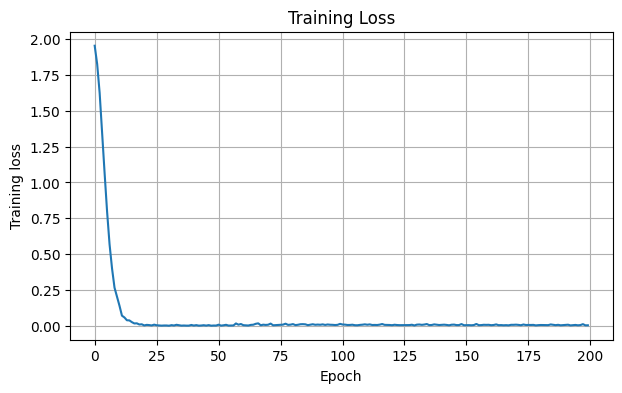

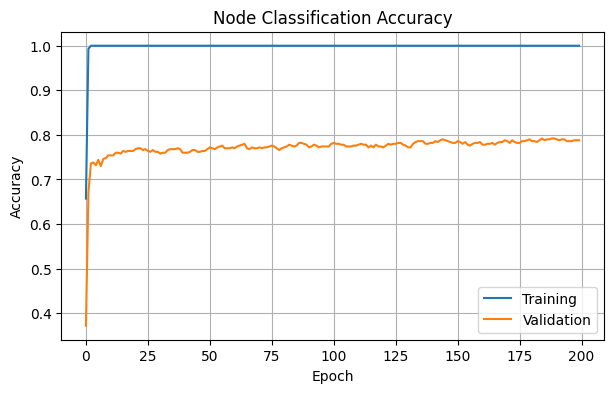

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["train_acc"], label="Training")
plt.plot(history["val_acc"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Node Classification Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## 7. What did the model learn?

Each message-passing layer allows information to travel one edge farther:
- After one layer, a node representation can include information from one-hop neighbours.
- After two layers, it can include information from nodes up to two hops away.

This is the node's **receptive field**.

More layers expand the receptive field, but deeper is not automatically better. Repeated aggregation can make node representations increasingly similar, a problem called **oversmoothing**.

Cora is a transductive node-classification task: graph structure and node features are available during training, while only a subset of labels contributes to the training loss.


In [12]:
@torch.no_grad()
def inspect_test_predictions(n=12):
    model.eval()
    log_probs = model(data.x, data.edge_index)
    probabilities = log_probs.exp()
    test_ids = data.test_mask.nonzero(as_tuple=False).view(-1)[:n]

    for node_id in test_ids.tolist():
        predicted = int(log_probs[node_id].argmax())
        true = int(data.y[node_id])
        confidence = float(probabilities[node_id, predicted])
        print(f"Node {node_id:4d} | true={true} | predicted={predicted} "
              f"| confidence={confidence:.3f}")

inspect_test_predictions()


Node 1708 | true=3 | predicted=2 | confidence=0.489
Node 1709 | true=2 | predicted=2 | confidence=0.991
Node 1710 | true=2 | predicted=2 | confidence=0.913
Node 1711 | true=2 | predicted=2 | confidence=1.000
Node 1712 | true=2 | predicted=2 | confidence=0.999
Node 1713 | true=0 | predicted=0 | confidence=0.232
Node 1714 | true=2 | predicted=2 | confidence=0.998
Node 1715 | true=2 | predicted=2 | confidence=0.999
Node 1716 | true=2 | predicted=2 | confidence=0.990
Node 1717 | true=2 | predicted=2 | confidence=0.999
Node 1718 | true=2 | predicted=2 | confidence=0.998
Node 1719 | true=2 | predicted=2 | confidence=0.999


## 8. Experiments

Run these experiments one at a time. Use the same data masks and compare validation accuracy and the test accuracy of the selected checkpoint.

**Experiment A — Aggregation:** Change `aggr="mean"` to `aggr="add"`. Does performance change? Why might node degree matter?

**Experiment B — Hidden dimension:** Try 16, 64, and 128 hidden channels. Compare parameter count, training time, and validation accuracy.

**Experiment C — Depth:** Add a third message-passing layer. Does the larger receptive field help? Watch for overfitting or oversmoothing.

**Experiment D — Self information:** Remove the self-feature part of the concatenation and use only `neighbor_mean`. How does performance change?

**Experiment E — Edge direction:** Reverse the edges using `edge_index.flip(0)`. Since Cora's graph representation generally includes both directions, reversing all edges may not change the result. Verify this experimentally.


## 9. Limitations and practical considerations

1. **Local information:** multiple layers are needed to propagate information across longer graph distances.
2. **Aggregation choice:** mean normalises by degree, sum retains magnitude information, and max selects feature-wise maxima.
3. **Oversmoothing:** deep message-passing networks can produce increasingly similar node representations.
4. **Computational cost:** large graphs can require substantial memory and computation; sampling and sparse operations may become important.
5. **Edge features:** this tutorial uses node features only. Many engineering problems also need edge features.
6. **Physical consistency:** a learned message is not automatically a conservative flux or physically correct interaction.

This is an educational implementation. For larger workloads, use optimised PyG layers and consider graph sampling and memory requirements.


## 10. Connecting message passing to computational meshes

An unstructured mesh can be represented as a graph. For example, mesh cells can become nodes and cell adjacency can become edges.

| Graph concept | Possible mesh interpretation |
|---|---|
| Node | Cell centre, mesh vertex, or control volume |
| Edge | Cell adjacency or mesh connectivity |
| Node features | Pressure, velocity, temperature, turbulence quantities |
| Edge features | Relative displacement, distance, face normal, face area |
| Message | Learned interaction between neighbouring entities |
| Aggregation | Combination of neighbouring information |
| Updated embedding | Latent representation of the local physical environment |

This creates opportunities for mesh-based surrogate modelling, reduced-order modelling, and learning on irregular physical domains.

However, a GNN does not automatically satisfy the conservation properties of a finite-volume solver. Conservation laws, boundary conditions, geometric consistency, and numerical stability must be considered explicitly. Possible approaches include antisymmetric pairwise exchanges, conservation constraints, and finite-volume-inspired message functions.

This is the bridge from general graph learning to scientific machine learning.


## 11. Final Challenge — Heat Diffusion on a Graph

Build a message-passing model for a simplified heat-diffusion problem.

- Represent a 2D mesh-like domain as a graph.
- Let each node represent a cell or point.
- Connect neighbouring cells or points with edges.
- Use initial temperature and optionally spatial coordinates as node features.
- Predict temperature at a later time.

Start with synthetic data generated from a simple diffusion equation.

Compare:
1. An MLP baseline that ignores graph connectivity.
2. A message-passing GNN.
3. An edge-aware GNN that uses relative position or distance.

Evaluate prediction error and investigate whether the predicted temperature field behaves as expected physically.

### Completion checklist

- [ ] I can explain message, aggregate, and update.
- [ ] I understand source-to-target edge direction.
- [ ] I implemented aggregation using `index_add_`.
- [ ] I understand sum, mean, and max aggregation.
- [ ] I implemented a custom PyG `MessagePassing` layer.
- [ ] I trained and evaluated a two-layer message-passing network.
- [ ] I understand how graph nodes and edges can represent a computational mesh.


## 12. Summary and What's Next?

We moved from using prebuilt graph-convolution layers to understanding the general message-passing mechanism. We implemented aggregation with plain PyTorch, reproduced it with PyG's `MessagePassing`, and trained a custom GraphSAGE-style model on Cora.

The central pattern is:

\[
\boxed{\text{Message}\rightarrow\text{Aggregate}\rightarrow\text{Update}}
\]

### Suggested Tutorial 6 — Graph Attention Networks (GAT) from First Principles

Our mean-aggregation layer treats all neighbours equally. But should every neighbour contribute equally?

In the next tutorial, we introduce attention mechanisms that allow a GNN to learn how much importance to assign to different neighbours. Later tutorials will move toward graph learning on meshes and scientific/engineering systems.

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**
